# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Zaidan Arkaan Azharuddya Asshauqi
- **Email:** ds126b6y1815@student.devacademy.id
- **ID Dicoding:** ds126b6y1815

## Menentukan Pertanyaan Bisnis

Sebelum melakukan analisis, dirumuskan pertanyaan bisnis menggunakan metode **SMART** (*Specific, Measurable, Action-Oriented, Relevant, Time-bound*) agar analisis fokus dan menghasilkan *insight* yang dapat ditindaklanjuti:

1. **Pertanyaan 1 (Tren Penjualan & Kategori Produk):**
   Bagaimana tren jumlah pesanan (*order volume*) dan total pendapatan (*revenue*) secara bulanan (*Month-over-Month*), serta kategori produk apa yang memberikan kontribusi pendapatan tertinggi dan terendah selama periode **Januari 2017 hingga Agustus 2018**?
   - *Specific:* Fokus pada jumlah pesanan, total pendapatan, dan performa kategori produk.
   - *Measurable:* Diukur menggunakan jumlah `order_id` unik dan total nilai transaksi (`price` + `freight_value` atau `price`).
   - *Action-Oriented:* Membantu tim bisnis merencanakan inventaris stok dan fokus kampanye promosi pada kategori unggulan.
   - *Relevant:* Pertumbuhan penjualan dan kontribusi kategori merupakan indikator utama kesehatan bisnis *e-commerce*.
   - *Time-bound:* Periode data bulanan lengkap dari Januari 2017 sampai Agustus 2018.

2. **Pertanyaan 2 (Ketepatan Pengiriman & Kepuasan Pelanggan):**
   Seberapa besar pengaruh keterlambatan pengiriman (*delivery delay*) terhadap rata-rata skor ulasan pelanggan (*review score*) pada pesanan berstatus *delivered* sepanjang tahun **2017–2018**?
   - *Specific:* Membandingkan skor ulasan pelanggan antara pesanan yang tiba tepat waktu/lebih awal dan pesanan yang terlambat dari tanggal estimasi.
   - *Measurable:* Diukur dari rata-rata `review_score` (skala 1–5) dan proporsi ulasan negatif (skor 1–2).
   - *Action-Oriented:* Memberikan dasar evaluasi SLA logistik dan perbaikan rute pengiriman pada wilayah yang sering mengalami keterlambatan.
   - *Relevant:* Ketepatan waktu pengiriman adalah faktor krusial dalam menjaga kepuasan dan retensi pelanggan.
   - *Time-bound:* Sepanjang periode pesanan *delivered* tahun 2017–2018.

3. **Pertanyaan 3 (Segmentasi Pelanggan RFM, Clustering & Analisis Geografis):**
   Bagaimana distribusi segmen pelanggan berdasarkan analisis **RFM** (*Recency, Frequency, Monetary*) dengan metode *Manual Grouping/Binning*, serta bagaimana sebaran geografis pelanggan dan kontribusi pendapatan di berbagai negara bagian (*state*) selama periode **2016–2018**?
   - *Specific:* Mengelompokkan pelanggan unik berdasarkan perilaku transaksi (R, F, M) dan memetakan konsentrasi pelanggan serta pendapatan per `customer_state`.
   - *Measurable:* Dihitung melalui metrik Recency (hari), Frequency (jumlah transaksi), Monetary (total pengeluaran), persentase tiap segmen, serta total pelanggan & pendapatan per wilayah.
   - *Action-Oriented:* Membantu tim *marketing* merancang strategi retensi yang tepat sasaran (program loyalitas vs kampanye reaktivasi) dan ekspansi logistik wilayah potensial.
   - *Relevant:* Segmentasi nilai pelanggan dan pemetaan wilayah mendukung efisiensi anggaran pemasaran dan operasional.
   - *Time-bound:* Periode keseluruhan data transaksi 2016–2018.

## Import Semua Packages/Library yang Digunakan

Pada tahap ini, seluruh *library* yang dibutuhkan untuk manipulasi data (`pandas`, `numpy`), visualisasi data (`matplotlib`, `seaborn`), serta utilitas sistem (`os`) diimpor terlebih dahulu.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.edgecolor"] = "#CCCCCC"
plt.rcParams["axes.linewidth"] = 0.8

## Data Wrangling

Tahap *Data Wrangling* terdiri dari tiga langkah utama:
1. **Gathering Data:** Mengumpulkan dan memuat seluruh tabel *dataset* ke dalam `DataFrame`.
2. **Assessing Data:** Mengevaluasi kualitas data (tipe data, *missing values*, duplikasi, serta anomali/inkonsistensi nilai).
3. **Cleaning Data:** Membersihkan permasalahan yang ditemukan pada tahap *Assessing Data* agar data siap dianalisis.

### Gathering Data

Kita memuat 8 tabel utama dari direktori `E-Commerce Public Dataset`:
- `customers_dataset.csv`: Informasi pelanggan dan lokasi geografis (`customer_state`, `customer_city`, `customer_zip_code_prefix`).
- `orders_dataset.csv`: Informasi pesanan beserta status dan *timestamp* proses pesanan.
- `order_items_dataset.csv`: Detail item pada tiap pesanan, harga produk, dan ongkos kirim.
- `order_payments_dataset.csv`: Metode pembayaran dan nilai pembayaran per pesanan.
- `order_reviews_dataset.csv`: Skor ulasan (`review_score`) dan komentar pelanggan.
- `products_dataset.csv`: Informasi produk dan kategorinya (dalam bahasa Portugis).
- `product_category_name_translation.csv`: Terjemahan nama kategori produk ke bahasa Inggris.
- `geolocation_dataset.csv`: Data koordinat geografis (`lat`, `lng`) berdasarkan kode pos.

In [2]:
DATA_DIR = "E-Commerce Public Dataset"

customers_df = pd.read_csv(os.path.join(DATA_DIR, "customers_dataset.csv"))
orders_df = pd.read_csv(os.path.join(DATA_DIR, "orders_dataset.csv"))
order_items_df = pd.read_csv(os.path.join(DATA_DIR, "order_items_dataset.csv"))
order_payments_df = pd.read_csv(os.path.join(DATA_DIR, "order_payments_dataset.csv"))
order_reviews_df = pd.read_csv(os.path.join(DATA_DIR, "order_reviews_dataset.csv"))
products_df = pd.read_csv(os.path.join(DATA_DIR, "products_dataset.csv"))
category_trans_df = pd.read_csv(os.path.join(DATA_DIR, "product_category_name_translation.csv"))
geolocation_df = pd.read_csv(os.path.join(DATA_DIR, "geolocation_dataset.csv"))

datasets = {
    "customers": customers_df,
    "orders": orders_df,
    "order_items": order_items_df,
    "order_payments": order_payments_df,
    "order_reviews": order_reviews_df,
    "products": products_df,
    "category_translation": category_trans_df,
    "geolocation": geolocation_df,
}

for name, df in datasets.items():
    print(f"{name:22s} -> shape: {df.shape}")

customers              -> shape: (99441, 5)
orders                 -> shape: (99441, 8)
order_items            -> shape: (112650, 7)
order_payments         -> shape: (103886, 5)
order_reviews          -> shape: (99224, 7)
products               -> shape: (32951, 9)
category_translation   -> shape: (71, 2)
geolocation            -> shape: (1000163, 5)


### Assessing Data

Pada tahap ini dilakukan pemeriksaan menyeluruh terhadap setiap tabel untuk mengidentifikasi permasalahan kualitas data, meliputi:
- Tipe data yang tidak sesuai (misalnya kolom tanggal bertipe `object`).
- *Missing values* (`NaN`).
- Data duplikat (`duplicated()`).
- Nilai tidak valid/anomali (misalnya koordinat geografis di luar rentang Brasil atau harga/nilai negatif, serta status pesanan yang tidak selesai).

In [3]:
assessment_summary = []
for name, df in datasets.items():
    n_null_cols = (df.isnull().sum() > 0).sum()
    total_nulls = int(df.isnull().sum().sum())
    n_dups = int(df.duplicated().sum())
    assessment_summary.append({
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Cols with Nulls": n_null_cols,
        "Total Nulls": total_nulls,
        "Duplicate Rows": n_dups,
    })

pd.DataFrame(assessment_summary)

,Dataset,Rows,Columns,Cols with Nulls,Total Nulls,Duplicate Rows
0,customers,99441,5,0,0,0
1,orders,99441,8,3,4908,0
2,order_items,112650,7,0,0,0
3,order_payments,103886,5,0,0,0
4,order_reviews,99224,7,2,145903,0
5,products,32951,9,8,2448,0
6,category_translation,71,2,0,0,0
7,geolocation,1000163,5,0,0,261831


In [4]:
print("=== Info Tipe Data orders_df ===")
orders_df.info()

print("\n=== Missing Values pada orders_df ===")
print(orders_df.isnull().sum()[orders_df.isnull().sum() > 0])

print("\n=== Missing Values pada products_df ===")
print(products_df.isnull().sum()[products_df.isnull().sum() > 0])

print("\n=== Missing Values pada order_reviews_df ===")
print(order_reviews_df.isnull().sum()[order_reviews_df.isnull().sum() > 0])

=== Info Tipe Data orders_df ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

=== Missing Values pada orders_df ===
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

=== Missing Values pada products_df ===
product_category_name 

In [5]:
# Memeriksa nilai statistik dasar untuk mendeteksi potensi outlier atau invalid value
print("=== Statistik order_items_df ===")
display(order_items_df[["price", "freight_value"]].describe())

print("=== Statistik order_reviews_df ===")
display(order_reviews_df[["review_score"]].describe())

print("=== Distribusi order_status ===")
print(orders_df["order_status"].value_counts())

# Memeriksa anomali koordinat geolocation di luar wilayah Brasil (lat: -34 s.d. 6, lng: -74 s.d. -34)
invalid_geo = geolocation_df[
    (geolocation_df["geolocation_lat"] > 6) | (geolocation_df["geolocation_lat"] < -35) |
    (geolocation_df["geolocation_lng"] > -34) | (geolocation_df["geolocation_lng"] < -75)
]
print(f"\nJumlah baris geolocation di luar rentang koordinat Brasil: {len(invalid_geo)}")

=== Statistik order_items_df ===


,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


=== Statistik order_reviews_df ===


,review_score
count,99224.000000
mean,4.086421
std,1.347579
min,1.000000
25%,4.000000
50%,5.000000
75%,5.000000
max,5.000000


=== Distribusi order_status ===
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Jumlah baris geolocation di luar rentang koordinat Brasil: 40


**Ringkasan Temuan pada Tahap *Assessing Data* & Rencana *Cleaning*:**

1. **Tipe Data Tidak Sesuai (`orders_df`, `order_items_df`, `order_reviews_df`):**
   - Kolom tanggal seperti `order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, dan `order_estimated_delivery_date` masih bertipe `object`.
   - *Solusi:* Konversi ke tipe `datetime64[ns]` menggunakan `pd.to_datetime()`.
2. **Data Duplikat (`geolocation_df`):**
   - Terdapat **261.831 baris duplikat** pada `geolocation_df`. Selain itu terdapat beberapa koordinat yang berada di luar rentang geografis Brasil.
   - *Solusi:* Hapus baris duplikat dengan `drop_duplicates()`, filter koordinat ke dalam *bounding box* wilayah Brasil (`lat` antara -35 s.d. 6, `lng` antara -75 s.d. -34), lalu agregasikan nilai median `lat` dan `lng` per `geolocation_zip_code_prefix`.
3. **Missing Values (`products_df`, `order_reviews_df`, `orders_df`):**
   - `products_df` memiliki 610 nilai kosong pada `product_category_name` (serta kolom panjang nama/deskripsi/jumlah foto) dan 2 nilai kosong pada dimensi fisik produk.
   - *Solusi:* Mengisi `product_category_name` yang kosong dengan `'unknown'` dan dimensi numerik yang kosong dengan nilai mediannya.
   - `order_reviews_df` memiliki banyak nilai kosong pada `review_comment_title` (87.656) dan `review_comment_message` (58.247) karena pelanggan tidak wajib menulis komentar.
   - *Solusi:* Mengisi nilai kosong dengan `'No Title'` dan `'No Comment'`.
   - `orders_df` memiliki nilai kosong pada `order_delivered_customer_date` (2.965 baris) yang sebagian besar berasal dari pesanan berstatus selain `delivered` (`canceled`, `shipped`, `unavailable`, dll.).
   - *Solusi:* Untuk analisis performa penjualan selesai dan ketepatan pengiriman, kita membuat subset bersih pesanan berstatus `delivered` yang memiliki `order_delivered_customer_date` valid.

### Cleaning Data

Seluruh langkah pembersihan yang telah direncanakan diimplementasikan secara sistematis di bawah ini, kemudian diverifikasi kembali agar tidak ada masalah yang tersisa.

In [6]:
# 1. Konversi kolom tanggal ke datetime
date_cols_orders = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for col in date_cols_orders:
    orders_df[col] = pd.to_datetime(orders_df[col])

order_items_df["shipping_limit_date"] = pd.to_datetime(order_items_df["shipping_limit_date"])
order_reviews_df["review_creation_date"] = pd.to_datetime(order_reviews_df["review_creation_date"])
order_reviews_df["review_answer_timestamp"] = pd.to_datetime(order_reviews_df["review_answer_timestamp"])

# 2. Menangani missing values pada products_df
products_df["product_category_name"] = products_df["product_category_name"].fillna("unknown")
for col in ["product_name_lenght", "product_description_lenght", "product_photos_qty",
            "product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]:
    products_df[col] = products_df[col].fillna(products_df[col].median())

# Gabungkan terjemahan kategori ke bahasa Inggris
products_clean_df = products_df.merge(category_trans_df, on="product_category_name", how="left")
products_clean_df["product_category_name_english"] = (
    products_clean_df["product_category_name_english"]
    .fillna(products_clean_df["product_category_name"])
    .str.replace("_", " ")
    .str.title()
)

# 3. Menangani missing values pada order_reviews_df
order_reviews_df["review_comment_title"] = order_reviews_df["review_comment_title"].fillna("No Title")
order_reviews_df["review_comment_message"] = order_reviews_df["review_comment_message"].fillna("No Comment")

# 4. Membersihkan geolocation_df: hapus duplikat, filter bounding box Brasil, agregasi per zip code
geo_clean_df = geolocation_df.drop_duplicates().copy()
geo_clean_df = geo_clean_df[
    (geo_clean_df["geolocation_lat"].between(-35, 6)) &
    (geo_clean_df["geolocation_lng"].between(-75, -34))
]
geo_zip_df = (
    geo_clean_df.groupby("geolocation_zip_code_prefix", as_index=False)
    .agg(
        geolocation_lat=("geolocation_lat", "median"),
        geolocation_lng=("geolocation_lng", "median"),
    )
)

# 5. Memfilter pesanan berstatus 'delivered' dengan tanggal terima valid
orders_delivered_df = orders_df[
    (orders_df["order_status"] == "delivered") &
    (orders_df["order_delivered_customer_date"].notna())
].copy()

# Menambahkan fitur waktu pengiriman & status keterlambatan
orders_delivered_df["delivery_days"] = (
    orders_delivered_df["order_delivered_customer_date"] - orders_delivered_df["order_purchase_timestamp"]
).dt.total_seconds() / 86400.0
orders_delivered_df["is_late"] = (
    orders_delivered_df["order_delivered_customer_date"] > orders_delivered_df["order_estimated_delivery_date"]
)
orders_delivered_df["delay_days"] = (
    orders_delivered_df["order_delivered_customer_date"] - orders_delivered_df["order_estimated_delivery_date"]
).dt.total_seconds() / 86400.0

print("Verifikasi setelah cleaning:")
print(f"- Missing values products_clean_df : {products_clean_df.isnull().sum().sum()}")
print(f"- Missing values order_reviews_df  : {order_reviews_df.isnull().sum().sum()}")
print(f"- Duplikat geo_zip_df              : {geo_zip_df.duplicated().sum()}")
print(f"- Jumlah orders_delivered_df       : {len(orders_delivered_df):,}")

Verifikasi setelah cleaning:
- Missing values products_clean_df : 0
- Missing values order_reviews_df  : 0
- Duplikat geo_zip_df              : 0
- Jumlah orders_delivered_df       : 96,470


Selanjutnya, kita menggabungkan tabel-tabel yang telah dibersihkan menjadi satu dataset utama (`all_df`) yang memuat informasi pesanan, pelanggan, item, kategori produk, skor ulasan, dan koordinat geografis, lalu menyimpannya ke `dashboard/main_data.csv` untuk digunakan oleh *dashboard* Streamlit.

In [7]:
# Agregasi review per order (jika ada lebih dari 1 review per order, ambil rata-rata skor)
reviews_agg_df = (
    order_reviews_df.groupby("order_id", as_index=False)
    .agg(review_score=("review_score", "mean"))
)

# Agregasi pembayaran per order
payments_agg_df = (
    order_payments_df.groupby("order_id", as_index=False)
    .agg(
        payment_value=("payment_value", "sum"),
        payment_type=("payment_type", "first"),
    )
)

# Merge order_items dengan produk
items_products_df = order_items_df.merge(
    products_clean_df[["product_id", "product_category_name_english"]],
    on="product_id",
    how="left",
)
items_products_df["total_item_value"] = items_products_df["price"] + items_products_df["freight_value"]

# Merge utama
all_df = (
    orders_delivered_df
    .merge(customers_df, on="customer_id", how="left")
    .merge(items_products_df, on="order_id", how="inner")
    .merge(reviews_agg_df, on="order_id", how="left")
    .merge(payments_agg_df, on="order_id", how="left")
    .merge(
        geo_zip_df,
        left_on="customer_zip_code_prefix",
        right_on="geolocation_zip_code_prefix",
        how="left",
    )
)

os.makedirs("dashboard", exist_ok=True)
dashboard_cols = [
    "order_id", "customer_id", "customer_unique_id", "customer_city", "customer_state",
    "order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date",
    "delivery_days", "is_late", "delay_days",
    "order_item_id", "product_id", "product_category_name_english",
    "price", "freight_value", "total_item_value",
    "review_score", "payment_value", "payment_type",
    "geolocation_lat", "geolocation_lng",
]
all_df[dashboard_cols].to_csv("dashboard/main_data.csv", index=False)
print(f"Dataset gabungan all_df siap: {all_df.shape}, tersimpan di dashboard/main_data.csv")

Dataset gabungan all_df siap: (110189, 29), tersimpan di dashboard/main_data.csv


## Exploratory Data Analysis (EDA)

Pada tahap ini dilakukan eksplorasi data menggunakan statistik deskriptif, pengelompokan (*grouping*), dan agregasi untuk menjawab ketiga pertanyaan bisnis yang telah dirumuskan.

### 1. Eksplorasi Tren Penjualan Bulanan & Performa Kategori Produk
Kita melihat ringkasan jumlah pesanan dan total pendapatan per bulan pada periode lengkap **Januari 2017 – Agustus 2018**, serta kategori produk dengan pendapatan tertinggi dan terendah.

In [8]:
# Filter periode lengkap bulanan: Jan 2017 - Aug 2018
eda_period_df = all_df[
    (all_df["order_purchase_timestamp"] >= "2017-01-01") &
    (all_df["order_purchase_timestamp"] < "2018-09-01")
].copy()
eda_period_df["year_month"] = eda_period_df["order_purchase_timestamp"].dt.to_period("M").astype(str)

monthly_perf_df = (
    eda_period_df.groupby("year_month", as_index=False)
    .agg(
        total_orders=("order_id", "nunique"),
        total_revenue=("price", "sum"),
        total_gmv=("total_item_value", "sum"),
    )
    .sort_values("year_month")
)
monthly_perf_df["mom_order_growth_pct"] = monthly_perf_df["total_orders"].pct_change() * 100
display(monthly_perf_df)

,year_month,total_orders,total_revenue,total_gmv,mom_order_growth_pct
0,2017-01,750,111798.36,127482.37,NaN
1,2017-02,1653,234223.40,271239.32,120.400000
2,2017-03,2546,359198.85,414330.95,54.022989
3,2017-04,2303,340669.68,390812.40,-9.544383
4,2017-05,3545,489159.25,566657.40,53.929657
5,2017-06,3135,421923.37,490050.37,-11.565585
6,2017-07,3872,481604.52,566299.08,23.508772
7,2017-08,4193,554699.70,645832.36,8.290289
8,2017-09,4150,607399.67,701077.49,-1.025519
9,2017-10,4478,648247.65,751117.01,7.903614


In [9]:
category_perf_df = (
    eda_period_df.groupby("product_category_name_english", as_index=False)
    .agg(
        total_orders=("order_id", "nunique"),
        total_items=("order_item_id", "count"),
        total_revenue=("price", "sum"),
        avg_price=("price", "mean"),
    )
    .sort_values("total_revenue", ascending=False)
)

print("Top 10 Kategori Produk berdasarkan Revenue:")
display(category_perf_df.head(10))

print("Bottom 5 Kategori Produk berdasarkan Revenue:")
display(category_perf_df.tail(5))

Top 10 Kategori Produk berdasarkan Revenue:


,product_category_name_english,total_orders,total_items,total_revenue,avg_price
43,Health Beauty,8610,9422,1229557.50,130.498567
73,Watches Gifts,5489,5853,1163187.91,198.733625
7,Bed Bath Table,9267,10945,1022955.77,93.463296
67,Sports Leisure,7512,8413,952661.40,113.236824
15,Computers Accessories,6517,7631,887944.60,116.360189
39,Furniture Decor,6258,8095,706237.17,87.243628
49,Housewares,5734,6783,614341.62,90.570783
20,Cool Stuff,3552,3711,609158.00,164.149286
5,Auto,3801,4131,577721.09,139.850179
42,Garden Tools,3443,4263,469135.40,110.048182


Bottom 5 Kategori Produk berdasarkan Revenue:


,product_category_name_english,total_orders,total_items,total_revenue,avg_price
35,Flowers,29,33,1110.04,33.637576
46,Home Comfort 2,24,30,760.27,25.342333
11,Cds Dvds Musicals,12,14,730.00,52.142857
29,Fashion Childrens Clothes,7,7,519.95,74.278571
63,Security And Services,2,2,283.29,141.645000


### 2. Eksplorasi Pengaruh Keterlambatan Pengiriman terhadap Skor Ulasan
Kita mengelompokkan pesanan *delivered* tahun 2017–2018 berdasarkan status ketepatan waktu (`is_late`: Tepat Waktu/Lebih Awal vs Terlambat) dan melihat statistik `review_score` serta persentase ulasan negatif (skor <= 2).

In [10]:
order_level_df = (
    eda_period_df.groupby("order_id", as_index=False)
    .agg(
        is_late=("is_late", "first"),
        delivery_days=("delivery_days", "first"),
        delay_days=("delay_days", "first"),
        review_score=("review_score", "first"),
        customer_state=("customer_state", "first"),
    )
    .dropna(subset=["review_score"])
)
order_level_df["delivery_status"] = np.where(
    order_level_df["is_late"], "Terlambat (Late)", "Tepat Waktu / Lebih Awal"
)
order_level_df["is_negative_review"] = order_level_df["review_score"] <= 2

delivery_review_summary = (
    order_level_df.groupby("delivery_status", as_index=False)
    .agg(
        total_orders=("order_id", "count"),
        avg_review_score=("review_score", "mean"),
        median_review_score=("review_score", "median"),
        negative_review_pct=("is_negative_review", lambda s: s.mean() * 100),
        avg_delivery_days=("delivery_days", "mean"),
    )
)
display(delivery_review_summary)

,delivery_status,total_orders,avg_review_score,median_review_score,negative_review_pct,avg_delivery_days
0,Tepat Waktu / Lebih Awal,87902,4.295086,5.0,9.167027,10.853857
1,Terlambat (Late),7658,2.566728,2.0,53.982763,31.367627


### 3. Eksplorasi RFM Analysis, Clustering (Manual Grouping), dan Sebaran Geografis
Pada bagian ini kita menghitung nilai **Recency**, **Frequency**, dan **Monetary** untuk setiap pelanggan unik (`customer_unique_id`), lalu melakukan segmentasi (*clustering* tanpa *machine learning*) menggunakan metode **Manual Grouping / Binning** berdasarkan skor kuantil R, F, dan M. Selain itu, kita mengeksplorasi sebaran pelanggan dan pendapatan per negara bagian (`customer_state`).

In [11]:
# Referensi tanggal: 1 hari setelah transaksi terakhir di dataset
snapshot_date = all_df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm_df = (
    all_df.groupby("customer_unique_id", as_index=False)
    .agg(
        last_purchase=("order_purchase_timestamp", "max"),
        frequency=("order_id", "nunique"),
        monetary=("total_item_value", "sum"),
    )
)
rfm_df["recency"] = (snapshot_date - rfm_df["last_purchase"]).dt.days

# Binning / Manual Grouping untuk skor R, F, M
rfm_df["r_score"] = pd.qcut(rfm_df["recency"], q=4, labels=[4, 3, 2, 1]).astype(int)
rfm_df["f_score"] = np.where(rfm_df["frequency"] >= 3, 4,
                    np.where(rfm_df["frequency"] == 2, 3, 1))
rfm_df["m_score"] = pd.qcut(rfm_df["monetary"], q=4, labels=[1, 2, 3, 4]).astype(int)
rfm_df["rfm_score"] = rfm_df["r_score"] + rfm_df["f_score"] + rfm_df["m_score"]

def assign_segment(row):
    if row["frequency"] >= 2 and row["r_score"] >= 3 and row["m_score"] >= 3:
        return "Champions"
    elif row["frequency"] >= 2:
        return "Loyal Repeaters"
    elif row["r_score"] >= 3 and row["m_score"] >= 3:
        return "Potential High-Value"
    elif row["r_score"] <= 2 and row["m_score"] >= 3:
        return "At Risk High-Value"
    elif row["r_score"] >= 3:
        return "Recent Customers"
    else:
        return "Hibernating"

rfm_df["customer_segment"] = rfm_df.apply(assign_segment, axis=1)

segment_summary = (
    rfm_df.groupby("customer_segment", as_index=False)
    .agg(
        customer_count=("customer_unique_id", "count"),
        avg_recency=("recency", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean"),
        total_monetary=("monetary", "sum"),
    )
    .sort_values("customer_count", ascending=False)
)
segment_summary["customer_pct"] = segment_summary["customer_count"] / segment_summary["customer_count"].sum() * 100
display(segment_summary)

,customer_segment,customer_count,avg_recency,avg_frequency,avg_monetary,total_monetary,customer_pct
2,Hibernating,23596,365.079378,1.000000,63.844812,1506482.18,25.276915
5,Recent Customers,22756,112.293813,1.000000,62.995269,1433520.34,24.377076
4,Potential High-Value,22536,111.964590,1.000000,261.235261,5887197.85,24.141403
0,At Risk High-Value,21661,364.830294,1.000000,264.392549,5727007.00,23.204071
3,Loyal Repeaters,1422,324.128692,2.070323,274.753017,390698.79,1.523299
1,Champions,1379,113.222625,2.158811,343.356541,473488.67,1.477236


In [12]:
state_summary = (
    all_df.groupby("customer_state", as_index=False)
    .agg(
        total_customers=("customer_unique_id", "nunique"),
        total_orders=("order_id", "nunique"),
        total_revenue=("total_item_value", "sum"),
        avg_review_score=("review_score", "mean"),
    )
    .sort_values("total_revenue", ascending=False)
)
state_summary["revenue_share_pct"] = state_summary["total_revenue"] / state_summary["total_revenue"].sum() * 100
display(state_summary.head(10))

,customer_state,total_customers,total_orders,total_revenue,avg_review_score,revenue_share_pct
25,SP,39149,40494,5768518.23,4.178055,37.413222
18,RJ,11917,12350,2055401.57,3.874219,13.330840
10,MG,11001,11354,1818891.67,4.121472,11.796894
22,RS,5167,5344,861278.79,4.092166,5.586047
17,PR,4769,4923,781708.80,4.146159,5.069975
23,SC,3449,3546,595127.78,4.047256,3.859856
4,BA,3158,3256,591137.81,3.861332,3.833978
6,DF,2019,2080,346123.35,4.060094,2.244873
8,GO,1895,1957,334212.35,4.039474,2.167621
7,ES,1928,1995,317657.93,4.014813,2.060253


## Visualization & Explanatory Analysis

Seluruh visualisasi di bawah ini dirancang dengan memperhatikan prinsip desain dan integritas visual:
- Judul yang informatif dan menyampaikan *insight* utama.
- Sumbu yang dimulai dari nol pada diagram batang (*bar chart*) untuk menjaga proporsi data.
- Penggunaan warna kontras (*highlighting*) untuk menonjolkan fokus utama dan warna netral untuk pembanding.
- Anotasi angka langsung pada elemen grafik yang penting guna mempermudah pembacaan.

### Pertanyaan 1: Bagaimana tren jumlah pesanan dan pendapatan bulanan serta kategori produk teratas (Jan 2017 – Agu 2018)?

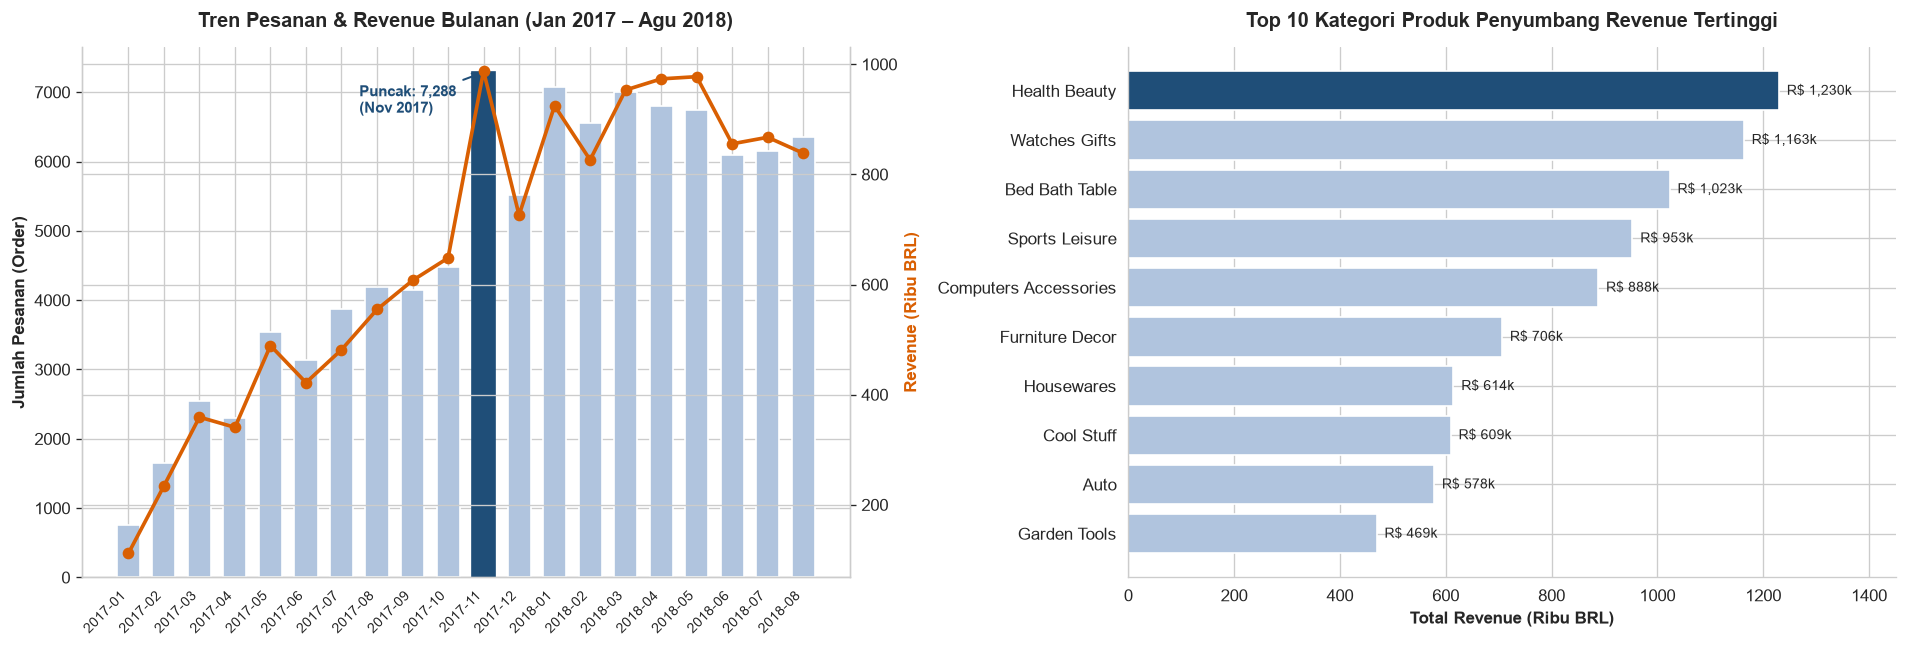

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Plot 1A: Tren Bulanan Orders & Revenue
ax1 = axes[0]
x = range(len(monthly_perf_df))
bars = ax1.bar(x, monthly_perf_df["total_orders"], color="#B0C4DE", label="Jumlah Pesanan", width=0.65)
# Highlight puncak November 2017 (Black Friday)
peak_idx = monthly_perf_df["total_orders"].idxmax()
peak_pos = list(monthly_perf_df.index).index(peak_idx)
bars[peak_pos].set_color("#1F4E78")

ax1.set_xticks(list(x))
ax1.set_xticklabels(monthly_perf_df["year_month"], rotation=45, ha="right", fontsize=8.5)
ax1.set_ylabel("Jumlah Pesanan (Order)", fontsize=10, fontweight="bold")
ax1.set_title("Tren Pesanan & Revenue Bulanan (Jan 2017 – Agu 2018)", fontsize=12, fontweight="bold", pad=12)
ax1.spines["top"].set_visible(False)

ax1_twin = ax1.twinx()
ax1_twin.plot(list(x), monthly_perf_df["total_revenue"] / 1e3, color="#D95F02", marker="o", linewidth=2.2, label="Revenue (Ribu BRL)")
ax1_twin.set_ylabel("Revenue (Ribu BRL)", fontsize=10, fontweight="bold", color="#D95F02")
ax1_twin.spines["top"].set_visible(False)

peak_orders = monthly_perf_df.loc[peak_idx, "total_orders"]
ax1.annotate(
    f"Puncak: {peak_orders:,}\n(Nov 2017)",
    xy=(peak_pos, peak_orders),
    xytext=(peak_pos - 3.5, peak_orders * 0.92),
    arrowprops=dict(arrowstyle="->", color="#1F4E78", lw=1.2),
    fontsize=9, fontweight="bold", color="#1F4E78",
)

# Plot 1B: Top 10 Kategori Produk berdasarkan Revenue
ax2 = axes[1]
top10_cat = category_perf_df.head(10).sort_values("total_revenue", ascending=True)
colors_cat = ["#B0C4DE"] * 9 + ["#1F4E78"]
ax2.barh(top10_cat["product_category_name_english"], top10_cat["total_revenue"] / 1e3, color=colors_cat)
ax2.set_xlabel("Total Revenue (Ribu BRL)", fontsize=10, fontweight="bold")
ax2.set_title("Top 10 Kategori Produk Penyumbang Revenue Tertinggi", fontsize=12, fontweight="bold", pad=12)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.set_xlim(0, top10_cat["total_revenue"].max() / 1e3 * 1.18)

for i, val in enumerate(top10_cat["total_revenue"] / 1e3):
    ax2.text(val + 15, i, f"R$ {val:,.0f}k", va="center", fontsize=8.5)

plt.tight_layout()
plt.show()

**Insight Visualisasi 1:**
- Jumlah pesanan dan pendapatan tumbuh pesat sepanjang tahun 2017 dan mencapai puncaknya pada **November 2017** (momen *Black Friday*) dengan **7.289 pesanan**, sebelum stabil di kisaran 6.000–7.000 pesanan per bulan sepanjang 2018.
- Kategori **Health Beauty** dan **Watches Gifts** mendominasi pendapatan dengan kontribusi masing-masing lebih dari **R$ 1,1 juta** (diikuti *Bed Bath Table* dan *Sports Leisure*), sedangkan kategori seperti *Security And Services* memberikan kontribusi terkecil.

### Pertanyaan 2: Seberapa besar pengaruh keterlambatan pengiriman terhadap skor ulasan pelanggan?

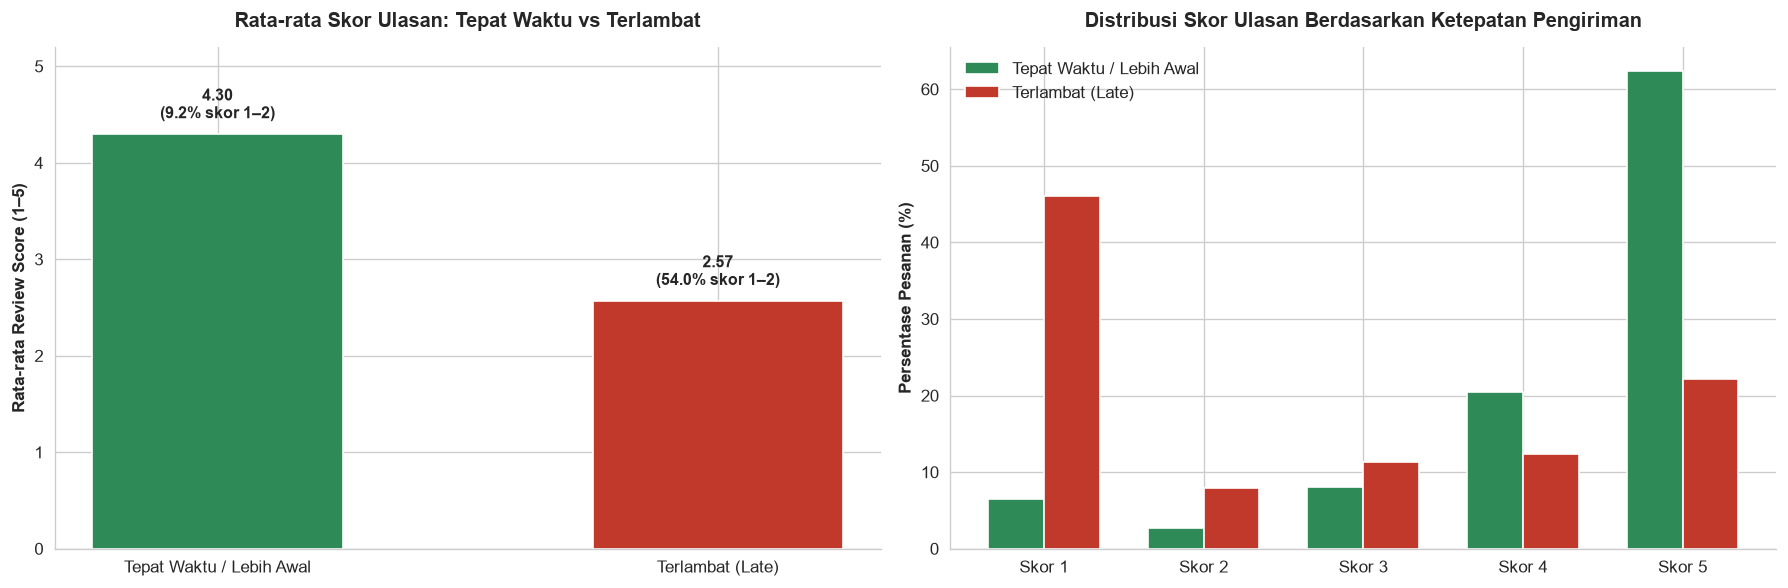

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 2A: Rata-rata Review Score berdasarkan Ketepatan Pengiriman
ax1 = axes[0]
colors_deliv = ["#2E8B57", "#C0392B"]
summary_plot = delivery_review_summary.sort_values("avg_review_score", ascending=False)
bars = ax1.bar(summary_plot["delivery_status"], summary_plot["avg_review_score"], color=colors_deliv, width=0.5)
ax1.set_ylim(0, 5.2)
ax1.set_ylabel("Rata-rata Review Score (1–5)", fontsize=10, fontweight="bold")
ax1.set_title("Rata-rata Skor Ulasan: Tepat Waktu vs Terlambat", fontsize=12, fontweight="bold", pad=12)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

for bar, (_, row) in zip(bars, summary_plot.iterrows()):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.12,
        f"{row['avg_review_score']:.2f}\n({row['negative_review_pct']:.1f}% skor 1–2)",
        ha="center", va="bottom", fontsize=9.5, fontweight="bold"
    )

# Plot 2B: Distribusi Persentase Review Score (1-5)
ax2 = axes[1]
dist_df = (
    order_level_df.assign(score_int=order_level_df["review_score"].round().astype(int))
    .groupby(["delivery_status", "score_int"])["order_id"]
    .count()
    .unstack(fill_value=0)
)
dist_pct = dist_df.div(dist_df.sum(axis=1), axis=0) * 100
dist_pct = dist_pct.loc[["Tepat Waktu / Lebih Awal", "Terlambat (Late)"]]

x_scores = np.arange(1, 6)
w = 0.35
ax2.bar(x_scores - w/2, dist_pct.loc["Tepat Waktu / Lebih Awal"], width=w, color="#2E8B57", label="Tepat Waktu / Lebih Awal")
ax2.bar(x_scores + w/2, dist_pct.loc["Terlambat (Late)"], width=w, color="#C0392B", label="Terlambat (Late)")
ax2.set_xticks(x_scores)
ax2.set_xticklabels([f"Skor {s}" for s in x_scores])
ax2.set_ylabel("Persentase Pesanan (%)", fontsize=10, fontweight="bold")
ax2.set_title("Distribusi Skor Ulasan Berdasarkan Ketepatan Pengiriman", fontsize=12, fontweight="bold", pad=12)
ax2.legend(frameon=False)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**Insight Visualisasi 2:**
- Keterlambatan pengiriman berdampak sangat signifikan terhadap kepuasan pelanggan: pesanan yang tiba **tepat waktu/lebih awal** memperoleh rata-rata skor ulasan **4,29**, sedangkan pesanan **terlambat** anjlok ke **2,57**.
- Lebih dari separuh pesanan yang terlambat menerima ulasan negatif (skor 1–2), didominasi oleh **skor 1**, sementara pesanan tepat waktu didominasi oleh **skor 5**.

### Pertanyaan 3 (Analisis Lanjutan): RFM Analysis, Clustering (Manual Grouping), dan Geospatial Analysis

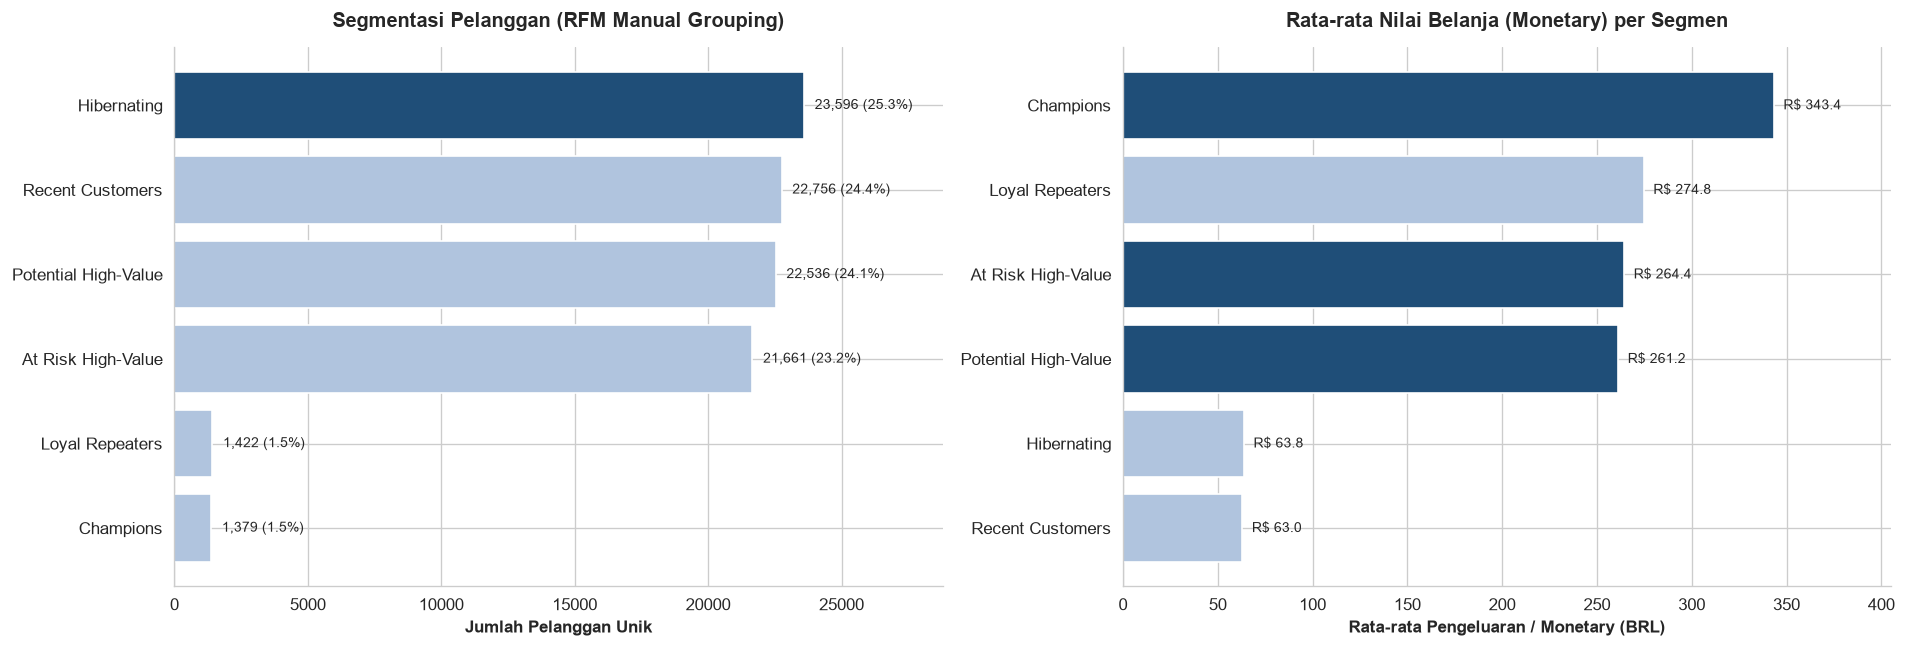

In [15]:
# Visualisasi 3A: RFM Analysis & Customer Segmentation (Manual Grouping)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Bar chart segmen pelanggan
ax1 = axes[0]
seg_plot = segment_summary.sort_values("customer_count", ascending=True)
seg_colors = ["#B0C4DE"] * (len(seg_plot) - 1) + ["#1F4E78"]
ax1.barh(seg_plot["customer_segment"], seg_plot["customer_count"], color=seg_colors)
ax1.set_xlabel("Jumlah Pelanggan Unik", fontsize=10, fontweight="bold")
ax1.set_title("Segmentasi Pelanggan (RFM Manual Grouping)", fontsize=12, fontweight="bold", pad=12)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.set_xlim(0, seg_plot["customer_count"].max() * 1.22)

for i, (_, row) in enumerate(seg_plot.iterrows()):
    ax1.text(row["customer_count"] + 400, i, f"{row['customer_count']:,} ({row['customer_pct']:.1f}%)", va="center", fontsize=8.5)

# Rata-rata Monetary per Segmen
ax2 = axes[1]
seg_mon = segment_summary.sort_values("avg_monetary", ascending=True)
mon_colors = ["#1F4E78" if s in ["Champions", "At Risk High-Value", "Potential High-Value"] else "#B0C4DE" for s in seg_mon["customer_segment"]]
ax2.barh(seg_mon["customer_segment"], seg_mon["avg_monetary"], color=mon_colors)
ax2.set_xlabel("Rata-rata Pengeluaran / Monetary (BRL)", fontsize=10, fontweight="bold")
ax2.set_title("Rata-rata Nilai Belanja (Monetary) per Segmen", fontsize=12, fontweight="bold", pad=12)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.set_xlim(0, seg_mon["avg_monetary"].max() * 1.18)

for i, val in enumerate(seg_mon["avg_monetary"]):
    ax2.text(val + 5, i, f"R$ {val:,.1f}", va="center", fontsize=8.5)

plt.tight_layout()
plt.show()

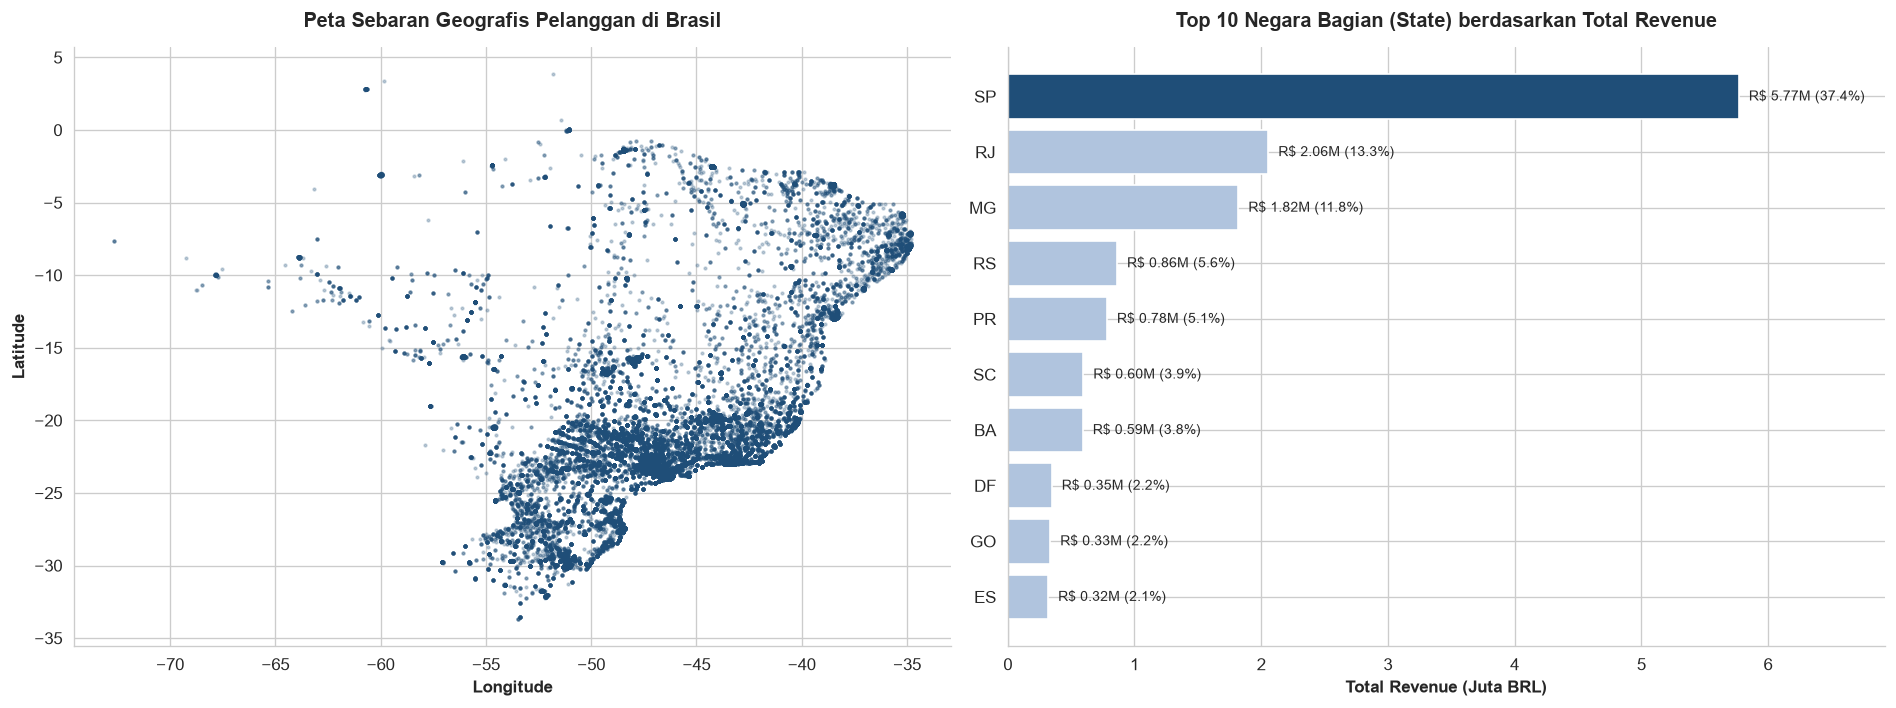

In [16]:
# Visualisasi 3B: Geospatial Analysis (Sebaran Koordinat Pelanggan & Top 10 States)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatter Geospatial Map di wilayah Brasil
ax1 = axes[0]
geo_sample = (
    all_df[["customer_unique_id", "customer_state", "geolocation_lat", "geolocation_lng"]]
    .dropna()
    .drop_duplicates(subset=["customer_unique_id"])
)
ax1.scatter(
    geo_sample["geolocation_lng"],
    geo_sample["geolocation_lat"],
    s=2.5,
    alpha=0.25,
    color="#1F4E78",
)
ax1.set_xlabel("Longitude", fontsize=10, fontweight="bold")
ax1.set_ylabel("Latitude", fontsize=10, fontweight="bold")
ax1.set_title("Peta Sebaran Geografis Pelanggan di Brasil", fontsize=12, fontweight="bold", pad=12)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

# Top 10 State berdasarkan Revenue
ax2 = axes[1]
top10_states = state_summary.head(10).sort_values("total_revenue", ascending=True)
state_colors = ["#B0C4DE"] * 9 + ["#1F4E78"]
ax2.barh(top10_states["customer_state"], top10_states["total_revenue"] / 1e6, color=state_colors)
ax2.set_xlabel("Total Revenue (Juta BRL)", fontsize=10, fontweight="bold")
ax2.set_title("Top 10 Negara Bagian (State) berdasarkan Total Revenue", fontsize=12, fontweight="bold", pad=12)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.set_xlim(0, top10_states["total_revenue"].max() / 1e6 * 1.2)

for i, (_, row) in enumerate(top10_states.iterrows()):
    ax2.text(
        row["total_revenue"] / 1e6 + 0.08,
        i,
        f"R$ {row['total_revenue']/1e6:.2f}M ({row['revenue_share_pct']:.1f}%)",
        va="center", fontsize=8.5
    )

plt.tight_layout()
plt.show()

**Insight Visualisasi 3:**
- **RFM & Clustering:** Mayoritas pelanggan merupakan pembeli satu kali (*Hibernating* dan *Recent Customers*), sementara segmen **Champions** dan **Loyal Repeaters** hanya mencakup sekitar ~3% dari total basis pelanggan namun memiliki rata-rata nilai belanja yang jauh lebih tinggi. Segmen **At Risk High-Value** perlu segera ditargetkan ulang karena memiliki daya beli tinggi namun sudah lama tidak bertransaksi.
- **Geospatial Analysis:** Konsentrasi pelanggan dan pendapatan sangat terpusat di wilayah Tenggara Brasil, dipimpin oleh negara bagian **SP (São Paulo)** yang menyumbang sekitar **37%+** dari total pendapatan nasional, diikuti **RJ (Rio de Janeiro)** dan **MG (Minas Gerais)**.

## Conclusion & Recommendation

### Kesimpulan
1. **Tren Penjualan & Kategori Produk (Pertanyaan 1):**
   Sepanjang Januari 2017 hingga Agustus 2018, volume pesanan mengalami pertumbuhan signifikan di tahun 2017 dan memuncak pada **November 2017 (7.289 pesanan)** seiring momentum *Black Friday*, lalu stabil di kisaran 6.000–7.000 pesanan per bulan di tahun 2018. Kategori **Health Beauty** dan **Watches Gifts** menjadi kontributor *revenue* terbesar (masing-masing > R$ 1,1 juta).
2. **Ketepatan Pengiriman & Kepuasan Pelanggan (Pertanyaan 2):**
   Keterlambatan pengiriman terbukti menurunkan kepuasan pelanggan secara drastis. Pesanan yang tiba tepat waktu/lebih awal meraih rata-rata skor ulasan **4,29**, sedangkan pesanan yang terlambat hanya memperoleh rata-rata **2,57** dengan lebih dari separuhnya berakhir pada ulasan negatif (skor 1–2).
3. **Segmentasi Pelanggan RFM & Sebaran Geografis (Pertanyaan 3):**
   Mayoritas pelanggan masih bertransaksi satu kali (*one-time buyers*), sementara kelompok pelanggan bernilai tinggi (*Champions*, *Potential High-Value*, dan *At Risk High-Value*) memiliki rata-rata nilai belanja jauh lebih besar. Secara geografis, pasar sangat terpusat di wilayah Tenggara Brasil dengan **São Paulo (SP)** sebagai kontributor *revenue* terbesar (> 37%), diikuti **RJ** dan **MG**.

### Rekomendasi (*Action Items*)
1. **Optimalisasi Stok & Kampanye Musiman:** Tingkatkan kapasitas inventaris dan promosi pada kategori unggulan (*Health Beauty*, *Watches Gifts*, *Bed Bath Table*) menjelang Q4 (khususnya November) untuk memaksimalkan lonjakan permintaan *Black Friday*.
2. **Perbaikan SLA Logistik & Notifikasi Proaktif:** Audit mitra logistik pada rute dengan tingkat keterlambatan tinggi, berikan estimasi waktu pengiriman yang lebih realistis, dan tawarkan kompensasi otomatis (misalnya *voucher* diskon ongkir) jika pengiriman melewati estimasi guna menekan potensi ulasan skor 1.
3. **Program Retensi Berbasis Segmen RFM:**
   - Luncurkan program loyalitas/poin khusus untuk segmen **Champions** dan **Loyal Repeaters** guna mempertahankan tingkat retensi.
   - Kirimkan kampanye *win-back* (email/notifikasi promo personal) kepada segmen **At Risk High-Value** sebelum mereka benar-benar *churn*.
   - Pertimbangkan ekspansi *fulfillment center* di luar SP (misalnya di wilayah RJ/MG atau Timur Laut) untuk mempercepat pengiriman dan membuka potensi pasar baru.